# 01 – Exploratory Data Analysis & Preprocessing

In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [111]:
df = pd.read_csv("../data/hotel_bookings.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [112]:
df.head() # first five rows of the data set

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In this data set there are 119390 rows and 32 columns.

## Duplicates

In [113]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 31994


In [114]:
df = df.drop_duplicates() 
df.shape

(87396, 32)

from 119390 rows, removed 31994 duplicate rows. Current dataframe shape (87396, 32)

## Missing values


In [115]:
missing = df.isnull().sum()
missing = missing[missing> 0]
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": missing_pct
}).sort_values("missing_count", ascending=False) # biggest problem first

missing_table


,missing_count,missing_percent
company,82137,93.98
agent,12193,13.95
country,452,0.52
children,4,0.00


### Missing values

After removing the 31,994 duplicate rows, 87,396 bookings remain. The percentages below are calculated on this cleaned data.

Four columns have missing values: `company`, `agent`, `country` and `children`.

- **company (93.98%)**: missing most likely means the booking was not made through a company. Instead of dropping the column, we convert it into a yes/no feature `has_company`.
- **agent (13.95%)**: missing most likely means the booking was made without a travel agent. Like company, it is an ID number, so we convert it into a yes/no feature `has_agent`.
- **country (0.52%)**: only a few rows are missing, so we fill them with "Unknown" instead of guessing a country.
- **children (4 rows)**: we fill these with 0, as this is the most common and most logical value.

In [116]:
# company: missing replaced with 1 and 0 -> 1 if booked through a company, 0 if not
df["has_company"] = df["company"].notna().astype(int)
# agent: missing replaced with 1 and 0 -> 1 if booked through an agent, 0 if not
df["has_agent"] = df["agent"].notna().astype(int)
# missing country fill with "Unknown"
df["country"] = df["country"].fillna("Unknown")
# Missing children values replaced with 0 
df["children"] = df["children"].fillna(0)
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,has_company,has_agent
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,0
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01,0,0
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,0,0
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02,0,1
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03,0,1


In [117]:
# Drop ID columns (company and agent )
df = df.drop(columns=["company", "agent"])

In [118]:
df.isnull().sum().sum()

np.int64(0)

## Invalid rows

In [119]:
df["total_guests"] = df["adults"] + df["children"] + df["babies"] 
(df["total_guests"] == 0).sum()

np.int64(166)

A booking without a guest is impossible. Therefore, these records are invalid and can be removed from the dataset.

In [120]:
# keep only bookings with at least 1 guest.
df = df[df["total_guests"]>0]
df.shape

(87230, 33)

`adr` is the average daily rate: the price per night in euros. A negative price is impossible, so it’s another data error.

In [121]:
# Remove booking with negative price
print((df["adr"] < 0).sum()) 
df = df[df["adr"] >= 0] 
df.shape

1


(87229, 33)

### Outliers in adr

In [122]:
df["adr"].describe()

count    87229.000000
mean       106.519325
std         54.890211
min          0.000000
25%         72.250000
50%         98.200000
75%        134.100000
max       5400.000000
Name: adr, dtype: float64

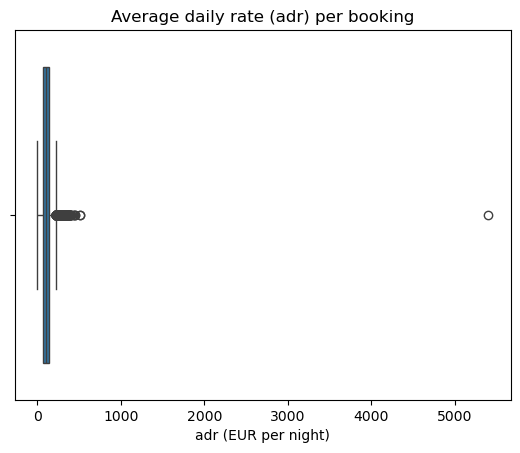

In [124]:
# box plot for 'adr'
sns.boxplot(x=df["adr"])
plt.title("Average daily rate (adr) per booking")
plt.xlabel("adr (EUR per night)")
plt.show()

In [ ]:
q1 = df["adr"].quantile(0.25)
q3 = df["adr"].quantile(0.75)
iqr = q3 - q1
upper =  q3 + 1.5 * iqr
print("upper fence:", upper)

SyntaxError: invalid syntax. Perhaps you forgot a comma? (3334353926.py, line 5)